# Skin Disease Classification using Convolution Neural Network

The **HAM10000 ("Human Against Machine with 10000 training images")** dataset.It consists of 10015 dermatoscopicimages which are released as a training set for academic machine learning purposes and are publiclyavailable through the ISIC archive. This benchmark dataset can be used for machine learning and for comparisons with human experts. 

It has 7 different classes of skin cancer which are listed below :<br>
**1. Melanocytic nevi (nv)<br>**
**2. Melanoma (mel) <br>**
**3. Benign keratosis-like lesions (bkl) <br>**
**4. Basal cell carcinoma (bcc)<br>**
**5. Actinic keratoses (akiec)<br>**
**6. Vascular lesions (vas) <br>**
**7. Dermatofibroma (df)<br>**

In this kernel I will try to detect 7 different classes of skin cancer using Convolution Neural Network with keras tensorflow in backend and then analyse the result to see how the model can be useful in practical scenario.<br>
We will move step by step process to classify 7 classes of cancer.

In this kernel I have followed following 14 steps for model building and evaluation which are as follows : <br>
**Step 1 : Importing Essential Libraries**<br>
**Step 2: Making Dictionary of images and labels** <br>
**Step 3: Reading and Processing Data** <br>
**Step 4: Data Cleaning** <br>
**Step 5: Exploratory data analysis (EDA)** <br>
**Step 6: Loading & Resizing of images **<br>
**Step 7: Train Test Split**<br>
**Step 8: Normalization**<br>
**Step 9: Label Encoding** <br>
**Step 10: Train validation split** <br>
**Step 11: Model Building (CNN)** <br>
**Step 12: Setting Optimizer & Annealing** <br>
**Step 13: Fitting the model**<br>
**Step 14: Model Evaluation (Testing and validation accuracy, confusion matrix, analysis of misclassified instances)** <br>

## Step 1 — Import libraries

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__)
print("Available devices:", tf.config.list_physical_devices())
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

I0000 00:00:1793182364.235714   13955 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793182364.306496   13955 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793182366.043498   13955 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.22.0-rc0
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 2 — Set the dataset path


HAM10000/<br>
|── HAM10000_metadata.csv <br>
|── HAM10000_images_part1/ <br>
└── HAM10000_images_part2/ 

In [6]:
DATA_DIR = Path(r"/home/rajeet16/skin-classification/HAM10000")  # CHANGE THIS PATH
METADATA_FILE = DATA_DIR / "/home/rajeet16/skin-classification/HAM10000/HAM10000_metadata.csv"

IMAGE_DIRS = [
    DATA_DIR / "/home/rajeet16/skin-classification/HAM10000/HAM10000_images_part_1",
    DATA_DIR / "/home/rajeet16/skin-classification/HAM10000/HAM10000_images_part_2",
]

if not METADATA_FILE.exists():
    raise FileNotFoundError(f"Metadata CSV not found: {METADATA_FILE}")

existing_image_dirs = [p for p in IMAGE_DIRS if p.exists()]
if not existing_image_dirs:
    raise FileNotFoundError(
        "Could not find image folders. Update IMAGE_DIRS to match your extracted dataset."
    )
print("Metadata:", METADATA_FILE)
print("Image folders:", existing_image_dirs)

Metadata: /home/rajeet16/skin-classification/HAM10000/HAM10000_metadata.csv
Image folders: [PosixPath('/home/rajeet16/skin-classification/HAM10000/HAM10000_images_part_1'), PosixPath('/home/rajeet16/skin-classification/HAM10000/HAM10000_images_part_2')]


## Step 3 — Read metadata and map image paths

In [7]:
skin_df = pd.read_csv(METADATA_FILE)

required_columns = {"image_id", "dx"}
missing_columns = required_columns - set(skin_df.columns)
if missing_columns:
    raise ValueError(f"Metadata is missing required columns: {missing_columns}")

image_lookup = {}
for image_dir in existing_image_dirs:
    for image_path in image_dir.glob("*.jpg"):
        image_lookup[image_path.stem] = str(image_path)

skin_df["path"] = skin_df["image_id"].map(image_lookup)
missing_images = skin_df["path"].isna().sum()
print("Rows in metadata:", len(skin_df))
print("Images not found:", missing_images)

skin_df = skin_df.dropna(subset=["path"]).copy()
skin_df.head()

Rows in metadata: 10015
Images not found: 0


,lesion_id,image_id,dx,dx_type,age,sex,localization,path
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/home/rajeet16/skin-classification/HAM10000/HA...
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/home/rajeet16/skin-classification/HAM10000/HA...
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/home/rajeet16/skin-classification/HAM10000/HA...
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/home/rajeet16/skin-classification/HAM10000/HA...
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/home/rajeet16/skin-classification/HAM10000/HA...


## Step 4 — Data cleaning

In [ ]:
print("Missing values before cleaning:")
display(skin_df.isnull().sum())
skin_df = skin_df.dropna(subset=["dx", "path"]).copy()

print("\nRows after cleaning:", len(skin_df))
print(skin_df.dtypes)

Missing values before cleaning:


lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
path             0
dtype: int64


Rows after cleaning: 10015
lesion_id           str
image_id            str
dx                  str
dx_type             str
age             float64
sex                 str
localization        str
path                str
dtype: object


Age and other descriptive metadata are not model inputs in this image-only CNN.<br>
Drop rows with missing labels or image paths; keep image data as the model input.

## Step 5 — Exploratory data analysis (EDA)
HAM10000 has seven diagnostic labels. The classes are imbalanced, so accuracy alone may not describe model performance well.

dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


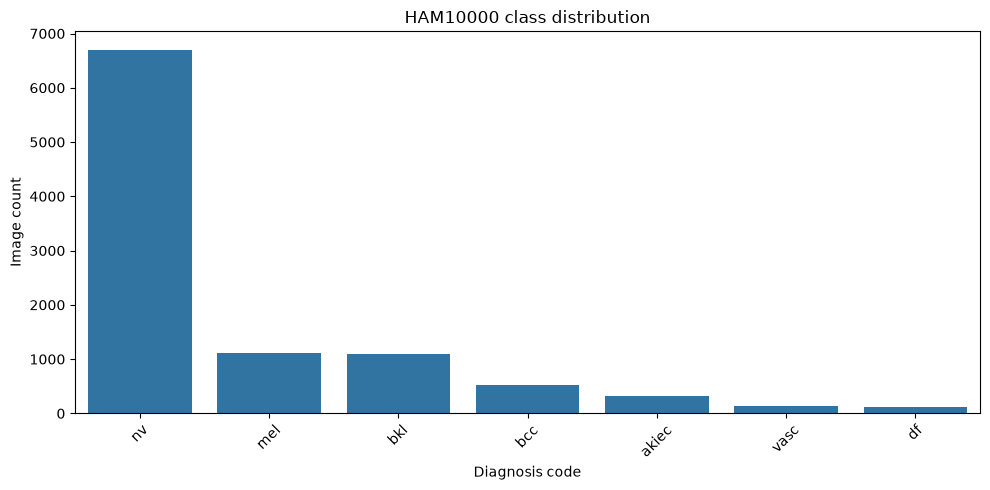

In [9]:
print(skin_df["dx"].value_counts())

plt.figure(figsize=(10, 5))
sns.countplot(data=skin_df, x="dx", order=skin_df["dx"].value_counts().index)
plt.title("HAM10000 class distribution")
plt.xlabel("Diagnosis code")
plt.ylabel("Image count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Dataset is certainly biased, can be observerd from above histogram.

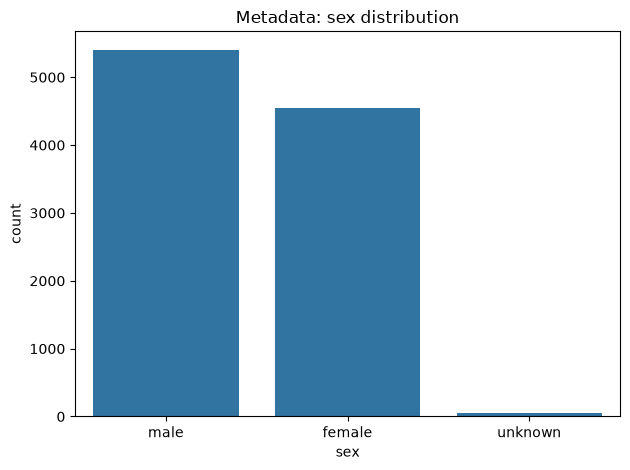

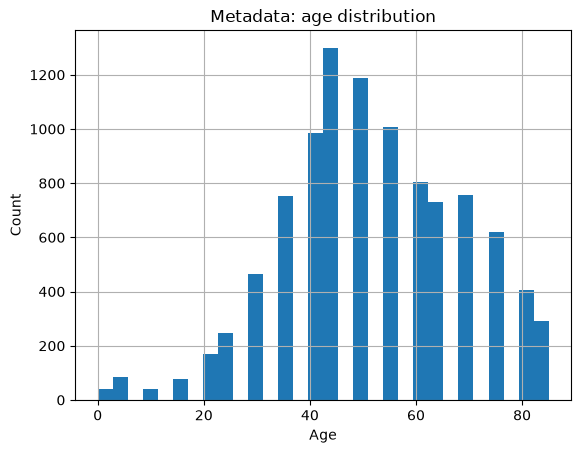

In [10]:
if "sex" in skin_df.columns:
    sns.countplot(data=skin_df, x="sex")
    plt.title("Metadata: sex distribution")
    plt.tight_layout()
    plt.show()

if "age" in skin_df.columns:
    skin_df["age"].hist(bins=30)
    plt.title("Metadata: age distribution")
    plt.xlabel("Age")
    plt.ylabel("Count")
    plt.show()

## Step 6 — Inspect images and define image size
Images will be loaded from disk by `tf.data`, rather than storing every decoded image in a large Pandas column.

Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Number of classes: 7


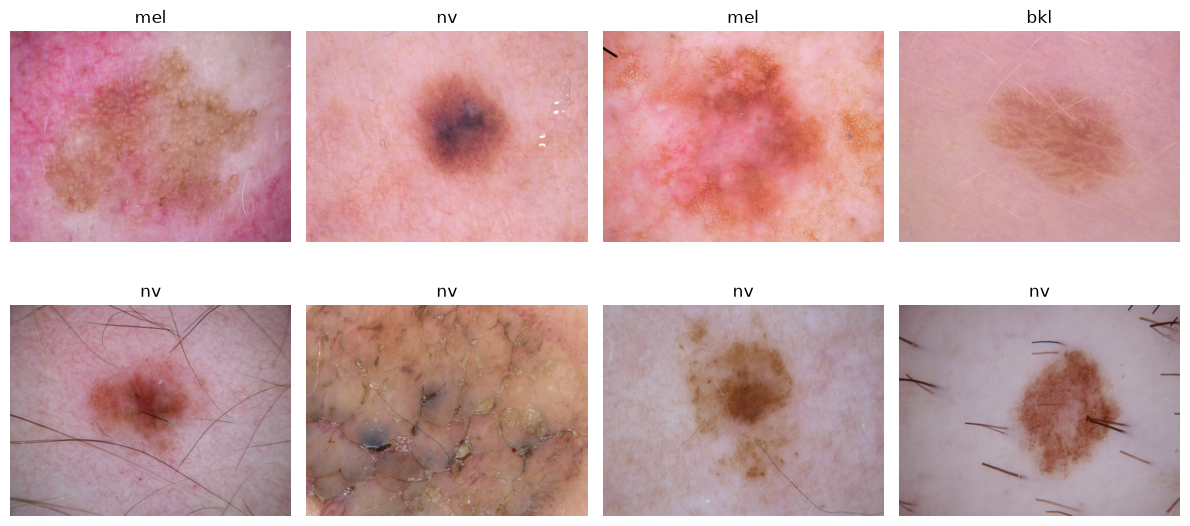

In [11]:
CLASS_NAMES = sorted(skin_df["dx"].unique())
NUM_CLASSES = len(CLASS_NAMES)
CLASS_TO_INDEX = {name: i for i, name in enumerate(CLASS_NAMES)}

IMAGE_HEIGHT = 128
IMAGE_WIDTH = 128
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

print("Classes:", CLASS_NAMES)
print("Number of classes:", NUM_CLASSES)

sample = skin_df.sample(min(8, len(skin_df)), random_state=RANDOM_SEED)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    with Image.open(row["path"]) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(row["dx"])
    ax.axis("off")
for ax in axes.flat[len(sample):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Step 7 — Train/test split

Use stratification to preserve class proportions. For skin-lesion datasets, duplicate images or multiple images from the same lesion can cause leakage if randomly split; HAM10000 includes `lesion_id`, so a lesion-wise split is preferable for a stricter evaluation.

In [12]:
skin_df["label"] = skin_df["dx"].map(CLASS_TO_INDEX).astype("int32")

if "lesion_id" in skin_df.columns and skin_df["lesion_id"].notna().all():
    # Keep images from the same lesion together.
    lesion_table = skin_df[["lesion_id", "label"]].drop_duplicates("lesion_id")
    train_lesions, test_lesions = train_test_split(
        lesion_table,
        test_size=0.20,
        random_state=RANDOM_SEED,
        stratify=lesion_table["label"],
    )
    train_df = skin_df[skin_df["lesion_id"].isin(train_lesions["lesion_id"])].copy()
    test_df = skin_df[skin_df["lesion_id"].isin(test_lesions["lesion_id"])].copy()
else:
    train_df, test_df = train_test_split(
        skin_df,
        test_size=0.20,
        random_state=RANDOM_SEED,
        stratify=skin_df["label"],
    )

print("Train images:", len(train_df))
print("Test images:", len(test_df))

Train images: 8020
Test images: 1995


## Step 8 — Build the input pipeline and normalize images
Pixel values are converted from `[0, 255]` to `[0, 1]` in the pipeline.

In [13]:
def load_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image_bytes, channels=3)
    image = tf.image.resize(image, [IMAGE_HEIGHT, IMAGE_WIDTH])
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def make_dataset(frame, training=False):
    paths = frame["path"].astype(str).to_numpy()
    labels = frame["label"].to_numpy(dtype=np.int32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(min(len(frame), 5000), seed=RANDOM_SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

## Step 9 — Encode labels
Labels are integer class indices and the model uses sparse categorical cross-entropy. This avoids the need for one-hot encoding.

In [14]:
print("Class mapping:")
for class_name, index in CLASS_TO_INDEX.items():
    print(f"{index}: {class_name}")

Class mapping:
0: akiec
1: bcc
2: bkl
3: df
4: mel
5: nv
6: vasc


## Step 10 — Create validation split
The validation set is separated from the training set. This simple image-level validation split is useful for iteration; for rigorous research, keep all images belonging to the same lesion in one split.

In [15]:
train_df, val_df = train_test_split(
    train_df,
    test_size=0.10,
    random_state=RANDOM_SEED,
    stratify=train_df["label"],
)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print(f"Train: {len(train_df)}, validation: {len(val_df)}, test: {len(test_df)}")

I0000 00:00:1793182727.161066   13955 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1767 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Train: 7218, validation: 802, test: 1995


## Step 11 — Build the CNN
This is a straightforward CNN baseline. Data augmentation is included in the model and is active only during training.

In [16]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.10),
    ],
    name="data_augmentation",
)

model = keras.Sequential([
    layers.Input(shape=(IMAGE_HEIGHT, IMAGE_WIDTH, 3)),
    data_augmentation,

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.20),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.30),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.40),
    layers.Dense(NUM_CLASSES, activation="softmax"),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 157,735 (616.15 KB)

 Trainable params: 157,287 (614.40 KB)

 Non-trainable params: 448 (1.75 KB)

## Step 12 — Compile the model and configure callbacks

In [17]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        "best_ham10000_cnn.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1,
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1,
    ),
]

## Step 13 — Train the model

Training time depends on your CPU/GPU, available RAM, and dataset location. Start with a small number of epochs to confirm everything works, then increase if needed.

In [18]:
EPOCHS = 30

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
)

Epoch 1/30


/home/rajeet16/skin-classification/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1793182744.281299   13955 meta_optimizer.cc:996] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/sequential_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1793182745.821710   15115 cuda_dnn.cc:442] Loaded cuDNN version 92700


226/226 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - accuracy: 0.6607 - loss: 0.9863
Epoch 1: val_loss improved from None to 2.39445, saving model to best_ham10000_cnn.keras

Epoch 1: finished saving model to best_ham10000_cnn.keras
226/226 ━━━━━━━━━━━━━━━━━━━━ 44s 145ms/step - accuracy: 0.6607 - loss: 0.9863 - val_accuracy: 0.1035 - val_loss: 2.3945 - learning_rate: 0.0010
Epoch 2/30
226/226 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.6783 - loss: 0.8899
Epoch 2: val_loss improved from 2.39445 to 2.00783, saving model to best_ham10000_cnn.keras

Epoch 2: finished saving model to best_ham10000_cnn.keras
226/226 ━━━━━━━━━━━━━━━━━━━━ 30s 131ms/step - accuracy: 0.6783 - loss: 0.8899 - val_accuracy: 0.2170 - val_loss: 2.0078 - learning_rate: 0.0010
Epoch 3/30
226/226 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - accuracy: 0.6922 - loss: 0.8426
Epoch 3: val_loss improved from 2.00783 to 1.29524, saving model to best_ham10000_cnn.keras

Epoch 3: finished saving model to best_ham10000_cnn.keras
226/226 ━

## Step 14 — Evaluate and save the model
Review test metrics and per-class results. A strong overall accuracy can hide poor performance on minority classes.

In [19]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.7424 - loss: 0.6769
Test loss: 0.6769
Test accuracy: 0.7424


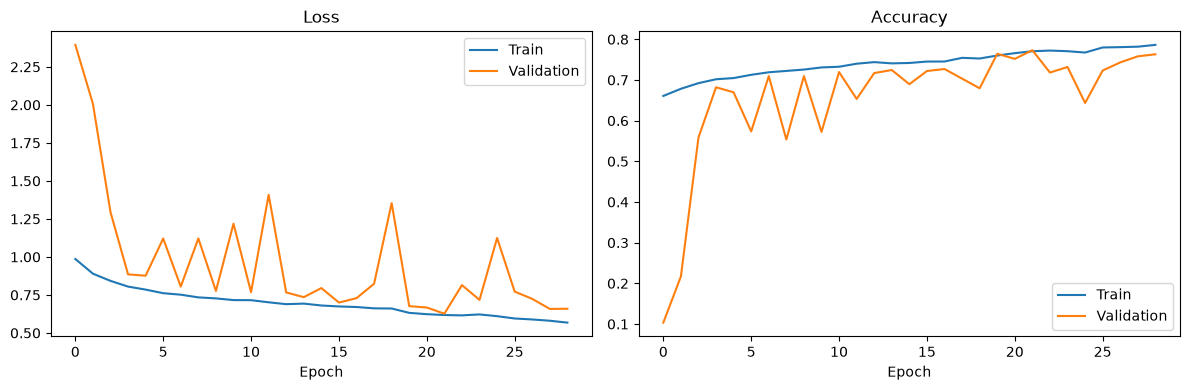

In [20]:
history_df = pd.DataFrame(history.history)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_df["loss"], label="Train")
plt.plot(history_df["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_df["accuracy"], label="Train")
plt.plot(history_df["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()
plt.tight_layout()
plt.show()

63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step
              precision    recall  f1-score   support

       akiec       0.34      0.39      0.36        62
         bcc       0.61      0.38      0.47       100
         bkl       0.41      0.55      0.47       218
          df       1.00      0.04      0.07        28
         mel       0.54      0.44      0.48       218
          nv       0.87      0.89      0.88      1337
        vasc       0.67      0.44      0.53        32

    accuracy                           0.74      1995
   macro avg       0.63      0.44      0.47      1995
weighted avg       0.75      0.74      0.74      1995



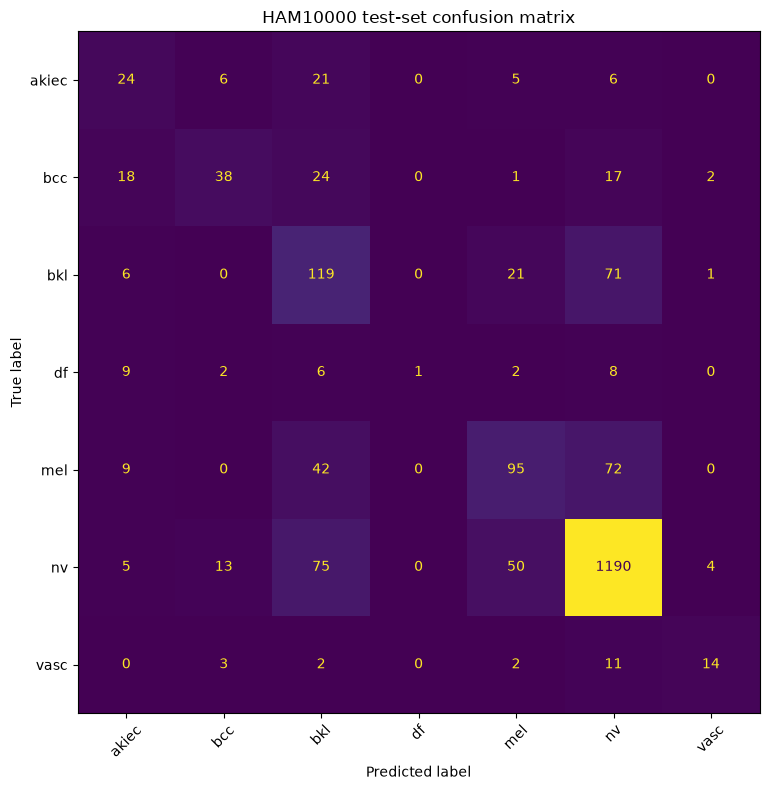

In [21]:
y_true = np.concatenate([labels.numpy() for _, labels in test_ds], axis=0)
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    zero_division=0,
))

cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("HAM10000 test-set confusion matrix")
plt.tight_layout()
plt.show()

In [22]:
model.save("ham10000_cnn_final.keras")
print("Saved model to:", Path("ham10000_cnn_final.keras").resolve())

Saved model to: /home/rajeet16/skin-classification/ham10000_cnn_final.keras


## Predict one new image

Set `image_path` to a skin image. The model returns a class prediction, not a diagnosis. Performance on ordinary phone photos may differ substantially from performance on HAM10000 dermatoscopic images.

In [26]:
def predict_skin_image(image_path):
    image_path = str(image_path)
    image_bytes = tf.io.read_file(image_path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image = tf.image.resize(image, [IMAGE_HEIGHT, IMAGE_WIDTH])
    image = tf.cast(image, tf.float32) / 255.0
    probabilities = model.predict(tf.expand_dims(image, axis=0), verbose=0)[0]
    best_index = int(np.argmax(probabilities))
    return {
        "predicted_class": CLASS_NAMES[best_index],
        "confidence": float(probabilities[best_index]),
        "all_probabilities": {
            CLASS_NAMES[i]: float(probabilities[i]) for i in range(NUM_CLASSES)
        },
    }

# Example:
result = predict_skin_image(r"/home/rajeet16/skin-classification/melanocytic.jpeg")
print(result)

{'predicted_class': 'nv', 'confidence': 0.9886881709098816, 'all_probabilities': {'akiec': 4.398917099024402e-06, 'bcc': 0.0021715096663683653, 'bkl': 0.0058671701699495316, 'df': 2.2845792045700364e-05, 'mel': 0.003245673608034849, 'nv': 0.9886881709098816, 'vasc': 2.728981769450911e-07}}


# Transfer Learning

In [37]:
base_model = keras.applications.MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet"
)

print("MobileNetV2 loaded successfully!")
print("Total layers:", len(base_model.layers))

MobileNetV2 loaded successfully!
Total layers: 154


In [38]:
base_model.trainable = False

print("MobileNetV2 layers frozen!")

MobileNetV2 layers frozen!


In [40]:
inputs = keras.Input(shape=(128, 128, 3))

# Your existing pipeline normalizes pixels to [0, 1].
# MobileNetV2 preprocessing expects [-1, 1].
x = layers.Rescaling(
    scale=2.0,
    offset=-1.0
)(inputs)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

# Seven HAM10000 classes
outputs = layers.Dense(
    7,
    activation="softmax"
)(x)

model_mobilenet = keras.Model(
    inputs=inputs,
    outputs=outputs
)

model_mobilenet.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,266,951 (8.65 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [41]:
model_mobilenet.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [43]:
model_mobilenet.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("MobileNetV2 model compiled successfully!")

MobileNetV2 model compiled successfully!


In [44]:
history_mobilenet = model_mobilenet.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    verbose=1
)

Epoch 1/10


I0000 00:00:1793185499.575614   15117 service.cc:154] XLA service 0x78558057c9d0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793185499.575728   15117 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 Laptop GPU, Compute Capability 8.6 (Driver: 12.9.0[576.88.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793185499.706417   15117 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


  7/226 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.5357 - loss: 1.5738 

I0000 00:00:1793185508.050499   15117 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


226/226 ━━━━━━━━━━━━━━━━━━━━ 41s 131ms/step - accuracy: 0.6748 - loss: 1.0140 - val_accuracy: 0.7382 - val_loss: 0.7081
Epoch 2/10
226/226 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.7325 - loss: 0.7568 - val_accuracy: 0.7469 - val_loss: 0.6547
Epoch 3/10
226/226 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.7508 - loss: 0.6955 - val_accuracy: 0.7668 - val_loss: 0.6297
Epoch 4/10
226/226 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.7660 - loss: 0.6464 - val_accuracy: 0.7718 - val_loss: 0.6293
Epoch 5/10
226/226 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.7720 - loss: 0.6306 - val_accuracy: 0.7693 - val_loss: 0.6281
Epoch 6/10
226/226 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.7786 - loss: 0.6069 - val_accuracy: 0.7756 - val_loss: 0.6572
Epoch 7/10
226/226 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.7832 - loss: 0.5865 - val_accuracy: 0.7706 - val_loss: 0.6319
Epoch 8/10
226/226 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.7868 - loss: 0.5691 - val_accuracy: 0.7

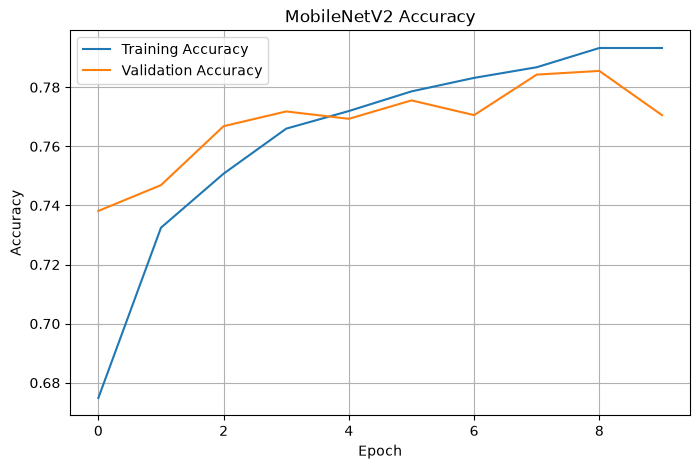

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history_mobilenet.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_mobilenet.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("MobileNetV2 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [48]:
test_loss, test_accuracy = model_mobilenet.evaluate(
    test_ds,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy (%): {test_accuracy * 100:.2f}%")

63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 141ms/step - accuracy: 0.7499 - loss: 0.7113
Test Loss: 0.7113
Test Accuracy: 0.7499
Test Accuracy (%): 74.99%


In [49]:
y_true = np.concatenate([
    labels.numpy()
    for _, labels in test_ds
])

y_prob = model_mobilenet.predict(test_ds, verbose=1)

y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=CLASS_NAMES,
    zero_division=0
))

63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 69ms/step
              precision    recall  f1-score   support

       akiec       0.53      0.26      0.35        62
         bcc       0.59      0.47      0.52       100
         bkl       0.42      0.51      0.46       218
          df       0.50      0.14      0.22        28
         mel       0.48      0.32      0.38       218
          nv       0.85      0.92      0.89      1337
        vasc       0.69      0.56      0.62        32

    accuracy                           0.75      1995
   macro avg       0.58      0.46      0.49      1995
weighted avg       0.73      0.75      0.74      1995



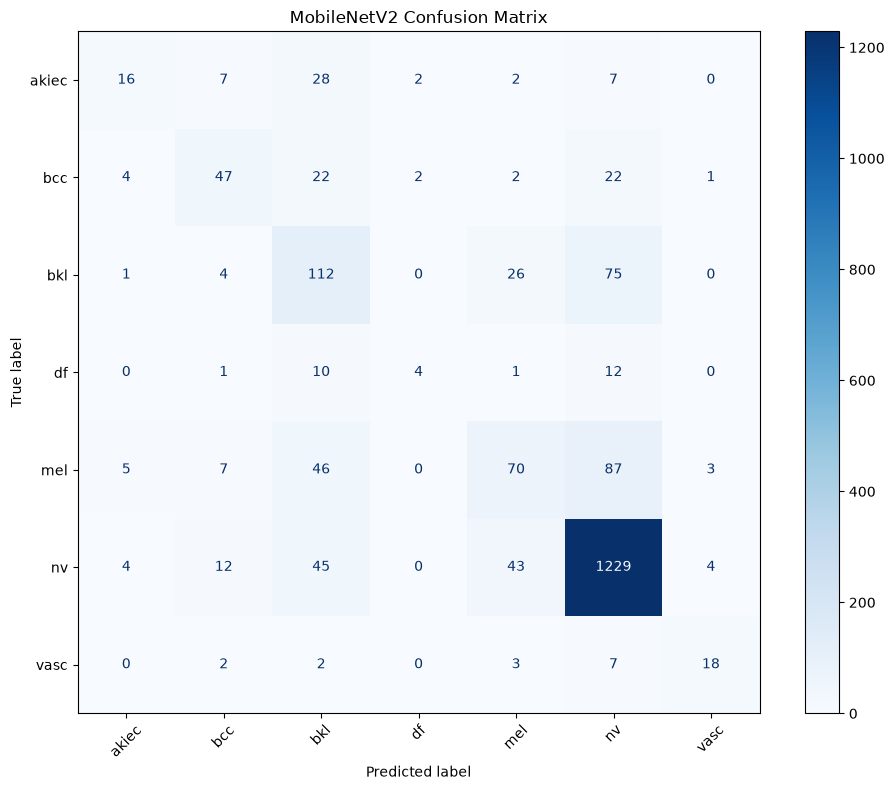

In [50]:
cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

fig, ax = plt.subplots(figsize=(10, 8))

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("MobileNetV2 Confusion Matrix")
plt.tight_layout()
plt.show()

In [51]:
mobilenet_results = {
    "Model": "MobileNetV2",
    "Test Loss": test_loss,
    "Test Accuracy": test_accuracy
}

print("MobileNetV2 Evaluation")
print("----------------------")

for key, value in mobilenet_results.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

MobileNetV2 Evaluation
----------------------
Model: MobileNetV2
Test Loss: 0.7113
Test Accuracy: 0.7499


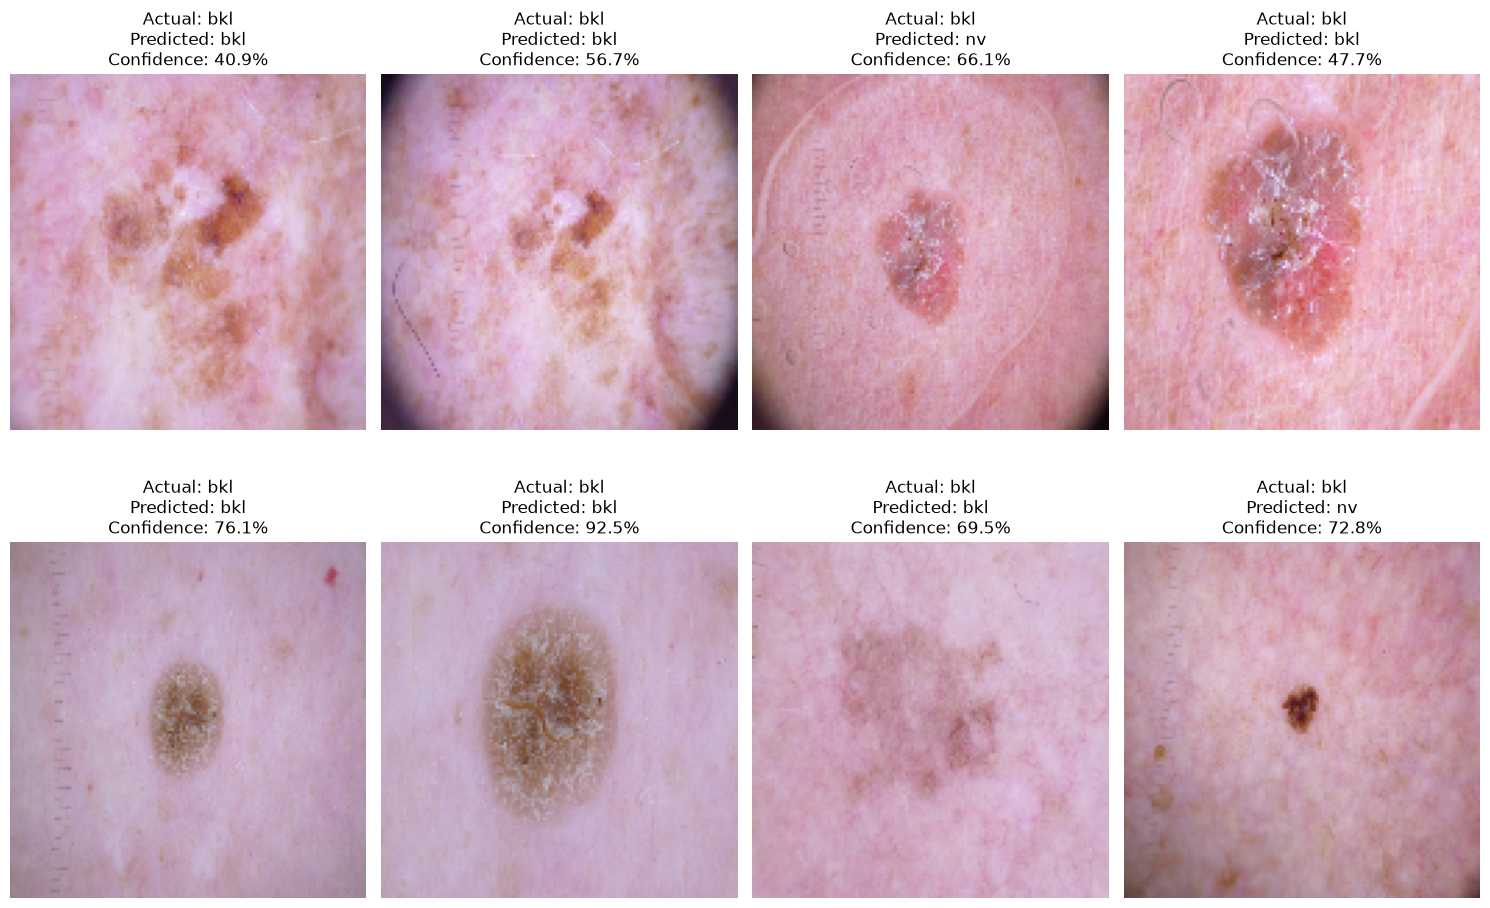

In [52]:
import matplotlib.pyplot as plt
import numpy as np

# Get one batch of test images and labels
for images, labels in test_ds.take(1):
    predictions = model_mobilenet.predict(images, verbose=0)

    predicted_classes = np.argmax(predictions, axis=1)
    actual_classes = labels.numpy()

    plt.figure(figsize=(15, 10))

    for i in range(min(8, len(images))):
        plt.subplot(2, 4, i + 1)

        plt.imshow(images[i].numpy())
        actual = CLASS_NAMES[actual_classes[i]]
        predicted = CLASS_NAMES[predicted_classes[i]]
        confidence = predictions[i][predicted_classes[i]] * 100

        plt.title(
            f"Actual: {actual}\n"
            f"Predicted: {predicted}\n"
            f"Confidence: {confidence:.1f}%"
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [46]:
model_mobilenet.save("ham10000_mobilenetv2.keras")

print("Model saved successfully!")

Model saved successfully!


In [47]:
import os

print(os.path.abspath("ham10000_mobilenetv2.keras"))

/home/rajeet16/skin-classification/ham10000_mobilenetv2.keras
